# Actividad individual 2 — Descubriendo patrones de tráfico con datos reales
## TC2035 — Diseño de Redes Neuronales y Aprendizaje Profundo

Nombre: Emilio Alonso Sánchez  
Matrícula: A00841853  
Grupo: 2  
Modalidad: Individual  
Herramienta: Google Colab (Python)  
Reto: Predicción inteligente de tiempos de verde — SEMEX

### Introducción

Esta actividad analiza los datos reales de tránsito de la intersección 01 del Distrito Tec, Monterrey, para comprender los patrones de demanda que podrían servir como entradas de una futura red neuronal.

Se utilizan tres archivos: mañana (07:00–10:00), mediodía (12:00–15:00) y tarde (17:00–20:00). En cada periodo se estudian los movimientos 1, 2 y 3 durante 12 intervalos de 15 minutos, para un total de 36 observaciones por movimiento. Se comparan los volúmenes, se identifican máximos horarios y se aplica normalización Min-Max a los tres periodos conjuntamente.

Las interpretaciones y la conclusión están basadas en los resultados obtenidos al ejecutar el análisis con los tres archivos. No se entrena una red neuronal, porque esta actividad se centra en comprender los datos.

### Contexto y correspondencia de los archivos

Los tres libros tienen 16 hojas: una de hora máxima, 14 hojas de movimientos (1–14) y una hoja de volúmenes direccionales. El croquis utiliza una nomenclatura ligeramente diferente para los periodos:

| Archivo Excel | Nombre usado en el notebook | Periodo en el croquis | Intervalo del estudio | Hora máxima del croquis |
|---|---|---|---|---|
| Int. 01 mañana.xlsx | Mañana | Mañana | 07:00–10:00 | 08:00–09:00: 1,771 vehículos |
| Int. 01 mediodia.xlsx | Mediodía | Tarde | 12:00–15:00 | 13:45–14:45: 2,287 vehículos |
| Int. 01 tarde.xlsx | Tarde | Noche | 17:00–20:00 | 17:15–18:15: 2,372 vehículos |

Estos valores representan toda la intersección en su hora de máxima demanda, no solamente los tres movimientos seleccionados. El código calculará las ventanas móviles de 60 minutos a partir de los registros reales para cotejarlas con el croquis.

Los movimientos se identifican por número según sus hojas respectivas. No se atribuye un giro o dirección específica sin una leyenda que lo confirme.

---

## Parte 1. Exploración y comprensión de los datos

### 1.1. Carga de los tres archivos

El notebook busca los tres archivos en el directorio de trabajo; cuando falta alguno, intenta descargarlo desde la rama main del repositorio. En Google Colab, si la descarga falla, permite subirlo desde la computadora.

Los archivos son libros Excel (.xlsx), no CSV. Se utilizará Pandas para su lectura, manteniendo las filas originales con encabezados especiales antes de extraer los intervalos y los movimientos.

In [12]:
# Importaciones y configuración: no se requiere TensorFlow para este análisis
from pathlib import Path
from io import BytesIO
from datetime import datetime, time
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 25)
pd.set_option("display.precision", 4)

# Nombres exactos que aparecen en el repositorio
PERIODOS = [
    {"periodo": "Mañana", "archivo": "Int. 01 mañana.xlsx",
     "hora_inicio": 7, "hora_fin": 10, "pico_croquis": 1771,
     "inicio_pico_croquis": "08:00", "nombre_croquis": "Mañana"},
    {"periodo": "Mediodía", "archivo": "Int. 01 mediodia.xlsx",
     "hora_inicio": 12, "hora_fin": 15, "pico_croquis": 2287,
     "inicio_pico_croquis": "13:45", "nombre_croquis": "Tarde"},
    {"periodo": "Tarde", "archivo": "Int. 01 tarde.xlsx",
     "hora_inicio": 17, "hora_fin": 20, "pico_croquis": 2372,
     "inicio_pico_croquis": "17:15", "nombre_croquis": "Noche"}
]
ORDEN_PERIODOS = [p["periodo"] for p in PERIODOS]
BASE_REPO = "https://raw.githubusercontent.com/A00841853/Redes-Neuronales/main/"

def obtener_excel(nombre):
    if Path(nombre).is_file():
        print("Archivo local:", nombre)
        return str(Path(nombre))
    import requests
    try:
        respuesta = requests.get(BASE_REPO + quote(nombre), timeout=20)
        respuesta.raise_for_status()
        if respuesta.content[:2] != b"PK":
            raise ValueError("La respuesta no es un archivo XLSX válido.")
        print("Archivo descargado de GitHub:", nombre)
        return BytesIO(respuesta.content)
    except Exception as error:
        print("No se pudo descargar", nombre, ":", error)
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError(
                f"Falta {nombre}. Descárgalo a la carpeta del notebook "
                "o ejecútalo en Colab para subirlo."
            ) from exc
        print("Sube el archivo:", nombre)
        subidos = files.upload()
        encontrado = next((k for k in subidos if k == nombre), None)
        if encontrado is None:
            raise FileNotFoundError(f"No se seleccionó el archivo esperado: {nombre}")
        return BytesIO(subidos[encontrado])

libros = {}
for p in PERIODOS:
    libros[p["periodo"]] = pd.ExcelFile(obtener_excel(p["archivo"]))

print("\nTres libros cargados:", ", ".join(libros.keys()))

Archivo local: Int. 01 mañana.xlsx
Archivo local: Int. 01 mediodia.xlsx
Archivo local: Int. 01 tarde.xlsx

Tres libros cargados: Mañana, Mediodía, Tarde


In [13]:
# Revisión de la estructura de los tres Excel
estructura = []
for periodo, libro in libros.items():
    hojas = libro.sheet_names
    estructura.append({
        "Periodo": periodo,
        "Hojas": len(hojas),
        "Movimientos numerados": sum(str(i) in hojas for i in range(1, 15)),
        "Contiene Hora Máx.": "Hora Máx." in hojas,
        "Contiene Vol. Dir.": "Vol. Dir." in hojas
    })
    print(periodo, "->", hojas)

tabla_estructura = pd.DataFrame(estructura)
display(tabla_estructura)

# Mostrar una vista original de las columnas usadas en cada periodo.
for p in PERIODOS:
    print(f"\nVista de movimiento 1 — {p['periodo']}:")
    original = pd.read_excel(libros[p["periodo"]], sheet_name="1", header=None)
    display(original.iloc[2:11, [0, 1, 4, 16]].fillna(""))

assert all(fila["Hojas"] == 16 and fila["Movimientos numerados"] == 14
           for fila in estructura)

Mañana -> ['Hora Máx.', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', 'Vol. Dir.']
Mediodía -> ['Hora Máx.', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', 'Vol. Dir.']
Tarde -> ['Hora Máx.', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', 'Vol. Dir.']


,Periodo,Hojas,Movimientos numerados,Contiene Hora Máx.,Contiene Vol. Dir.
0,Mañana,16,14,True,True
1,Mediodía,16,14,True,True
2,Tarde,16,14,True,True



Vista de movimiento 1 — Mañana:


,0,1,4,16
2,,,Int. 01 Av.Eugenio Gza. Sada - Del Estado - Av...,
3,,,mov. 1,
4,,,Soleado,
5,,,,
6,,,,
7,LAPSO,,BTR,TOTAL
8,H:MIN,H:MIN,,
9,07:00:00,07:15:00,,39
10,07:15:00,07:30:00,,59



Vista de movimiento 1 — Mediodía:


,0,1,4,16
2,,,Int. 01 Av.Eugenio Gza. Sada - Del Estado - Av...,
3,,,mov. 1,
4,,,Soleado,
5,,,,
6,,,,
7,LAPSO,,BTR,TOTAL
8,H:MIN,H:MIN,,
9,12:00:00,12:15:00,,77
10,12:15:00,12:30:00,,69



Vista de movimiento 1 — Tarde:


,0,1,4,16
2,,,Int. 01 Av.Eugenio Gza. Sada - Del Estado - Av...,
3,,,mov. 1,
4,,,Soleado,
5,,,,
6,,,,
7,LAPSO,,BTR,TOTAL
8,H:MIN,H:MIN,,
9,17:00:00,17:15:00,,89
10,17:15:00,17:30:00,,93


### Interpretación 1. Comprendiendo los datos

¿Qué representa cada registro? Cada fila de la tabla combinada corresponde a un intervalo de 15 minutos y contiene los volúmenes de los movimientos 1, 2 y 3 observados en ese mismo intervalo. Se reunieron 12 intervalos de mañana, 12 de mediodía y 12 de tarde, es decir, 36 registros en total.

¿Qué variables se identificaron? El periodo del día, la hora inicial y final del intervalo, los tres volúmenes por movimiento y su suma. En los archivos originales también se incluyen clasificaciones vehiculares por categorías y datos resumidos de toda la intersección. Cada movimiento está identificado en una hoja distinta.

¿Qué unidades tienen los volúmenes? Los conteos de cada movimiento se expresan en vehículos por 15 minutos. Los acumulados mostrados en la gráfica de barras corresponden a tres horas de observación por periodo; las horas máximas del croquis representan ventanas de una hora.

¿Qué información es útil? Los perfiles por intervalo, las diferencias entre movimientos, los cambios de demanda según el periodo, la composición vehicular y las horas de máxima demanda.

¿Se requirió limpieza? Sí. Los tres libros contienen 16 hojas cada uno, encabezados en varias filas y separadores entre grupos de registros. Se extrajeron los tiempos de las columnas A y B y el volumen total de la columna Q de cada hoja de movimiento. El resultado contiene 36 registros completos, sin volúmenes faltantes. No fue necesario reconstruir ningún total a partir de las categorías vehiculares.

### 1.2. Extracción de los movimientos e intervalos

En los tres libros, cada movimiento aparece en su propia hoja numerada. Las columnas A y B registran el inicio y fin del intervalo, mientras que la columna Q almacena el volumen TOTAL del movimiento. Las columnas C:P contienen categorías de vehículos.

Se leen directamente las mismas hojas 1, 2 y 3 en cada periodo. Cuando una celda de Q carezca del resultado almacenado de su fórmula de Excel, el código reconstruirá ese total sumando exclusivamente las categorías vehiculares disponibles de esa misma fila. Si no hay ni total ni conteos de categorías, se notificará un error, en lugar de inventar datos.

El análisis reunirá 12 intervalos por periodo, para un total de 36 intervalos distintos.

In [14]:
# Utilidades para extraer horas, totales y categorías de cada hoja
def leer_hora(valor):
    if pd.isna(valor):
        return None
    if isinstance(valor, (pd.Timestamp, datetime, time)):
        return f"{valor.hour:02d}:{valor.minute:02d}"
    if isinstance(valor, (int, float, np.number)) and not isinstance(valor, bool):
        x = float(valor)
        if 0 <= x < 1:
            minutos = round(x * 24 * 60) % (24 * 60)
            return f"{minutos // 60:02d}:{minutos % 60:02d}"
    if isinstance(valor, str):
        import re
        match = re.match(r"^\s*(\d{1,2}):(\d{2})", valor)
        if match:
            h, m = map(int, match.groups())
            if h < 24 and m < 60:
                return f"{h:02d}:{m:02d}"
    return None

def minutos_de_hora(h):
    return int(h[:2]) * 60 + int(h[3:5])

registro_reconstrucciones = []

def leer_movimiento(libro, periodo, numero, hora_inicio, hora_fin):
    """Usa A=inicio, B=fin, Q=total; reconstruye Q desde C:P si falta."""
    crudo = pd.read_excel(libro, sheet_name=str(numero), header=None)
    inicio = crudo.iloc[:, 0].map(leer_hora)
    fin = crudo.iloc[:, 1].map(leer_hora)
    hora_num = inicio.fillna("00:00").str[:2].astype(int)
    mascara = inicio.notna() & fin.notna() & hora_num.between(hora_inicio, hora_fin - 1)

    q = pd.to_numeric(crudo.iloc[:, 16], errors="coerce")
    categorias = crudo.iloc[:, 2:16].apply(pd.to_numeric, errors="coerce")
    suma_categorias = categorias.sum(axis=1, min_count=1)

    # Si Q no tiene el valor almacenado, se recupera de C:P sin crear datos.
    falta_q = mascara & q.isna()
    reconstruidos = int((falta_q & suma_categorias.notna()).sum())
    total = q.where(q.notna(), suma_categorias)

    # La presencia de una fila con hora y sin ningún conteo no se interpreta como cero.
    if total.loc[mascara].isna().any():
        raise ValueError(f"Hay intervalos sin dato de volumen en {periodo}, movimiento {numero}.")

    # Comprobar la coherencia del total cuando existen tanto Q como categorías.
    ambos = mascara & q.notna() & suma_categorias.notna()
    if (np.abs(q.loc[ambos] - suma_categorias.loc[ambos]) > 0.01).any():
        raise ValueError(f"El total Q no coincide con las categorías C:P en {periodo}, movimiento {numero}.")

    nombre = f"Movimiento {numero}"
    tabla = pd.DataFrame({
        "Intervalo": inicio.loc[mascara].to_numpy(),
        "Fin": fin.loc[mascara].to_numpy(),
        nombre: total.loc[mascara].to_numpy()
    })
    tabla[nombre] = pd.to_numeric(tabla[nombre])
    tabla = tabla.sort_values(
        "Intervalo", key=lambda c: c.map(minutos_de_hora)
    ).reset_index(drop=True)

    esperados = [f"{h:02d}:{m:02d}"
                 for h in range(hora_inicio, hora_fin)
                 for m in (0, 15, 30, 45)]
    if tabla["Intervalo"].tolist() != esperados:
        raise ValueError(f"Intervalos inesperados en {periodo}, movimiento {numero}.")
    registro_reconstrucciones.append({
        "Periodo": periodo, "Movimiento": numero,
        "Totales Q reconstruidos desde C:P": reconstruidos
    })
    return tabla

print("Funciones preparadas para leer mañana, mediodía y tarde.")

Funciones preparadas para leer mañana, mediodía y tarde.


---

## Parte 2. Selección y visualización de movimientos vehiculares

Se seleccionan los movimientos 1, 2 y 3, que están presentes en los tres archivos. Se obtendrán 36 filas: 12 intervalos matutinos, 12 de mediodía y 12 de tarde. Al unirlos se preservará la etiqueta de periodo para evitar conectar horarios separados como si fueran observaciones continuas.

El análisis comparará tanto la demanda dentro de cada periodo como los volúmenes acumulados en las tres horas de cada levantamiento. Además, se contrastará la hora de máxima demanda de toda la intersección con los datos de la hoja Hora Máx. y las cifras del croquis.

In [15]:
# Construir una tabla conjunta de los tres libros: 36 intervalos x 3 movimientos
movimientos = ["Movimiento 1", "Movimiento 2", "Movimiento 3"]
tablas = []

for info in PERIODOS:
    periodo = info["periodo"]
    libro = libros[periodo]
    series = [
        leer_movimiento(libro, periodo, numero,
                        info["hora_inicio"], info["hora_fin"])
        for numero in (1, 2, 3)
    ]
    subtabla = series[0]
    for serie in series[1:]:
        subtabla = subtabla.merge(
            serie, on=["Intervalo", "Fin"], how="inner", validate="one_to_one"
        )
    if len(subtabla) != 12:
        raise ValueError(f"Se esperaban 12 intervalos coincidentes en {periodo}.")
    subtabla.insert(0, "Periodo", periodo)
    subtabla["Minuto inicio"] = subtabla["Intervalo"].map(minutos_de_hora)
    subtabla["Suma de tres movimientos"] = subtabla[movimientos].sum(axis=1)
    tablas.append(subtabla)

datos = pd.concat(tablas, ignore_index=True)
datos["Periodo"] = pd.Categorical(
    datos["Periodo"], categories=ORDEN_PERIODOS, ordered=True
)

assert len(datos) == 36
assert datos.groupby("Periodo", observed=True).size().eq(12).all()
assert datos[movimientos].notna().all().all()

print("Tabla conjunta de los tres periodos:")
display(datos[["Periodo", "Intervalo", "Fin", *movimientos]])

print("\nReconstrucciones de totales Q (si eran necesarias):")
display(pd.DataFrame(registro_reconstrucciones))
print("Total de registros combinados:", len(datos))
print("Valores faltantes:", datos[movimientos].isna().sum().to_dict())

Tabla conjunta de los tres periodos:


,Periodo,Intervalo,Fin,Movimiento 1,Movimiento 2,Movimiento 3
0,Mañana,07:00,07:15,39.0,20.0,8.0
1,Mañana,07:15,07:30,59.0,32.0,12.0
2,Mañana,07:30,07:45,86.0,38.0,17.0
3,Mañana,07:45,08:00,60.0,47.0,28.0
4,Mañana,08:00,08:15,72.0,60.0,20.0
5,Mañana,08:15,08:30,57.0,37.0,14.0
6,Mañana,08:30,08:45,89.0,39.0,20.0
7,Mañana,08:45,09:00,73.0,43.0,24.0
8,Mañana,09:00,09:15,75.0,72.0,17.0
9,Mañana,09:15,09:30,76.0,32.0,12.0



Reconstrucciones de totales Q (si eran necesarias):


,Periodo,Movimiento,Totales Q reconstruidos desde C:P
0,Mañana,1,0
1,Mañana,2,0
2,Mañana,3,0
3,Mediodía,1,0
4,Mediodía,2,0
5,Mediodía,3,0
6,Tarde,1,0
7,Tarde,2,0
8,Tarde,3,0


Total de registros combinados: 36
Valores faltantes: {'Movimiento 1': 0, 'Movimiento 2': 0, 'Movimiento 3': 0}


In [16]:
# Tabla de acumulados por periodo y por movimiento
totales_periodo = datos.groupby("Periodo", observed=True)[movimientos].sum()
totales_periodo["Total movimientos 1–3"] = totales_periodo[movimientos].sum(axis=1)
display(Markdown("### Volúmenes acumulados en cada periodo de 3 horas"))
display(totales_periodo.astype(int))

# Comprobar los máximos horarios de toda la intersección con la hoja "Hora Máx."
# La hora pico puede comenzar a los 00, 15, 30 o 45 minutos.
registros_picos = []
intervalos_interseccion = {}

for info in PERIODOS:
    periodo = info["periodo"]
    tabla = pd.read_excel(libros[periodo], sheet_name="Hora Máx.", header=None)
    inicio = tabla.iloc[:, 0].map(leer_hora)
    fin = tabla.iloc[:, 1].map(leer_hora)
    horas = inicio.fillna("00:00").str[:2].astype(int)
    mascara = (
        inicio.notna() & fin.notna() &
        horas.between(info["hora_inicio"], info["hora_fin"] - 1)
    )

    total_inter = pd.to_numeric(tabla.iloc[:, 4], errors="coerce")
    base = pd.DataFrame({
        "Inicio": inicio.loc[mascara].to_numpy(),
        "Fin": fin.loc[mascara].to_numpy(),
        "Total intersección": total_inter.loc[mascara].to_numpy()
    })
    base = base.sort_values(
        "Inicio", key=lambda c: c.map(minutos_de_hora)
    ).reset_index(drop=True)

    if len(base) != 12 or base["Total intersección"].isna().any():
        raise ValueError(f"Datos incompletos en Hora Máx. para {periodo}.")

    # Ventanas móviles de cuatro intervalos de 15 minutos = 60 minutos
    movil = base["Total intersección"].rolling(4).sum()
    fin_ventana = int(movil.idxmax())
    principio_ventana = fin_ventana - 3
    hora_pico_inicio = base.loc[principio_ventana, "Inicio"]
    hora_pico_fin = base.loc[fin_ventana, "Fin"]
    volumen_pico = int(movil.iloc[fin_ventana])

    # Los tres movimientos se comparan en exactamente la misma hora.
    tres = datos.loc[datos["Periodo"] == periodo].reset_index(drop=True)
    volumen_tres = int(tres.iloc[principio_ventana:fin_ventana + 1][movimientos].sum().sum())

    registros_picos.append({
        "Periodo": periodo,
        "Hora pico inicio": hora_pico_inicio,
        "Hora pico fin": hora_pico_fin,
        "Intersección completa": volumen_pico,
        "Movimientos 1–3 en esa hora": volumen_tres,
        "Referencia croquis": info["pico_croquis"]
    })
    intervalos_interseccion[periodo] = base

    assert volumen_pico == info["pico_croquis"], \
        f"Volumen de hora pico no coincide con croquis en {periodo}."
    assert hora_pico_inicio == info["inicio_pico_croquis"], \
        f"Inicio de hora pico no coincide con croquis en {periodo}."

picos = pd.DataFrame(registros_picos).set_index("Periodo")
display(Markdown("### Hora máxima de cada periodo: Excel frente a croquis"))
display(picos)
print("Verificación satisfactoria: los tres valores de hora pico coinciden con el croquis.")

### Volúmenes acumulados en cada periodo de 3 horas

,Movimiento 1,Movimiento 2,Movimiento 3,Total movimientos 1–3
Periodo,,,,
Mañana,842,491,188,1521
Mediodía,919,644,233,1796
Tarde,1187,780,179,2146


### Hora máxima de cada periodo: Excel frente a croquis

,Hora pico inicio,Hora pico fin,Intersección completa,Movimientos 1–3 en esa hora,Referencia croquis
Periodo,,,,,
Mañana,08:00,09:00,1771,548,1771
Mediodía,13:45,14:45,2287,619,2287
Tarde,17:15,18:15,2372,722,2372


Verificación satisfactoria: los tres valores de hora pico coinciden con el croquis.


### 2.2. Relación con el croquis

El código calcula, para mañana, mediodía y tarde, las horas de máxima demanda a partir de la hoja Hora Máx. y verifica que coincidan con los totales publicados: 1,771, 2,287 y 2,372 vehículos. Esto evita confundir el volumen de toda la intersección con la suma de los movimientos 1, 2 y 3.

La suma de los movimientos seleccionados en cada hora pico se presenta por separado en la tabla de resultados. Las tres corrientes se mantienen identificadas con sus números originales. Para asignar un giro concreto o un sentido preciso a cada una sería necesaria la equivalencia del estudio.

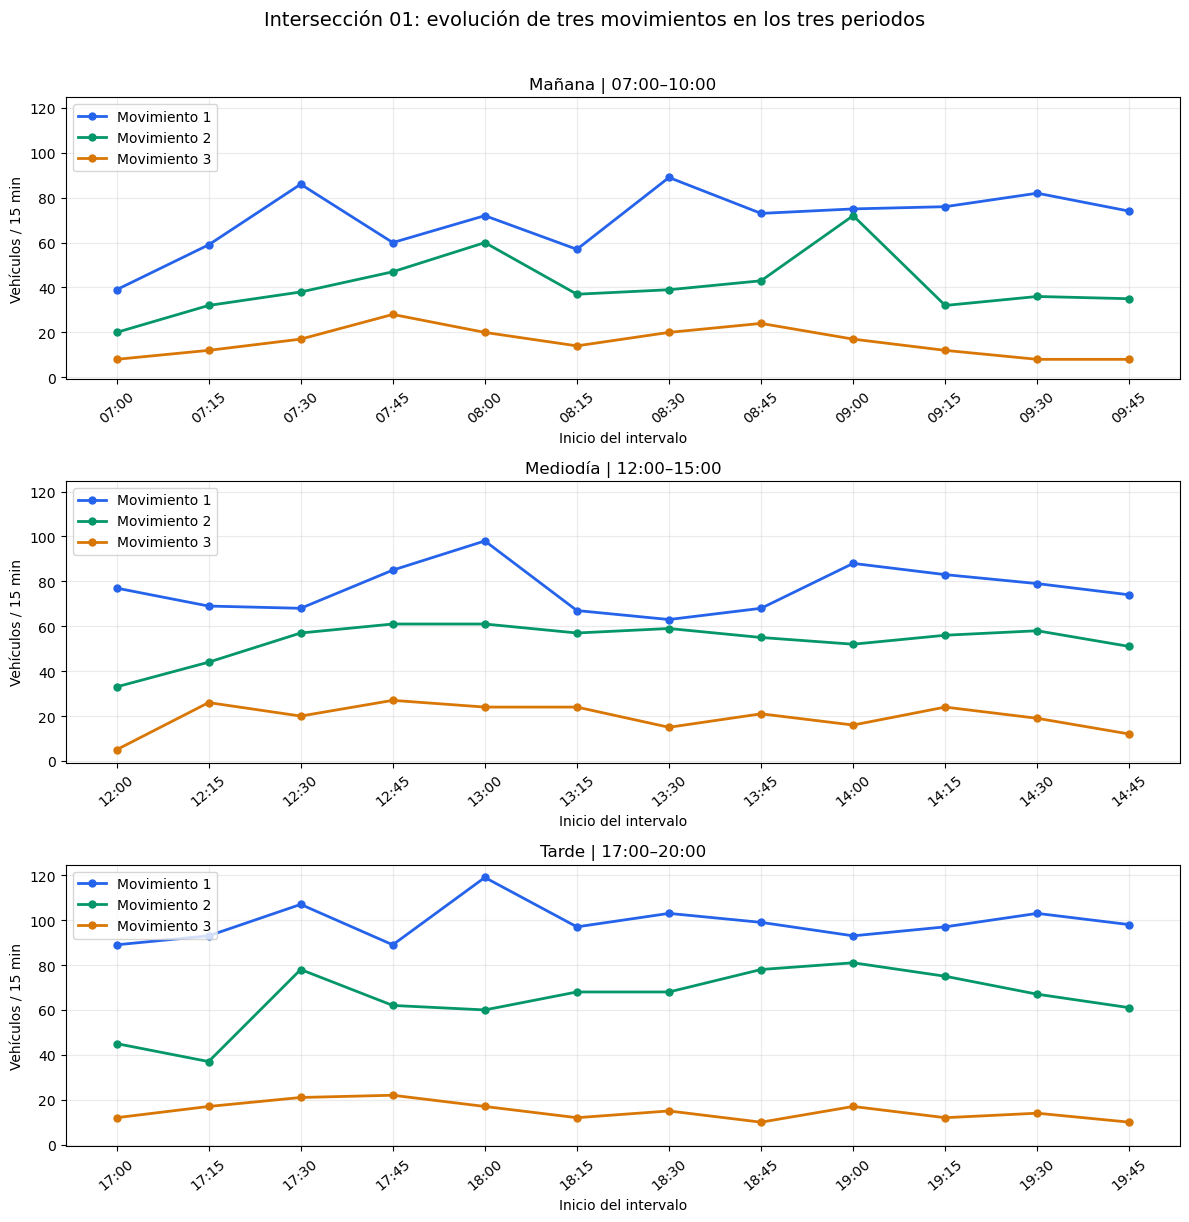

In [17]:
# Gráfica 1: evolución de los movimientos 1, 2 y 3, separados por periodo
# Los saltos entre 10:00, 12:00 y 17:00 NO se unen con líneas artificiales.
fig, ejes = plt.subplots(3, 1, figsize=(12, 12), sharey=True)
colores = ["#2563eb", "#059669", "#d97706"]

for ax, info in zip(ejes, PERIODOS):
    periodo = info["periodo"]
    sub = datos.loc[datos["Periodo"] == periodo]
    for nombre, color in zip(movimientos, colores):
        ax.plot(sub["Intervalo"], sub[nombre],
                marker="o", linewidth=2, markersize=5,
                label=nombre, color=color)
    ax.set_title(f"{periodo} | {info['hora_inicio']:02d}:00–{info['hora_fin']:02d}:00")
    ax.set_ylabel("Vehículos / 15 min")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper left")
    ax.tick_params(axis="x", labelrotation=40)
    ax.set_xlabel("Inicio del intervalo")

fig.suptitle("Intersección 01: evolución de tres movimientos en los tres periodos",
             fontsize=14, y=1.015)
plt.tight_layout()
plt.show()

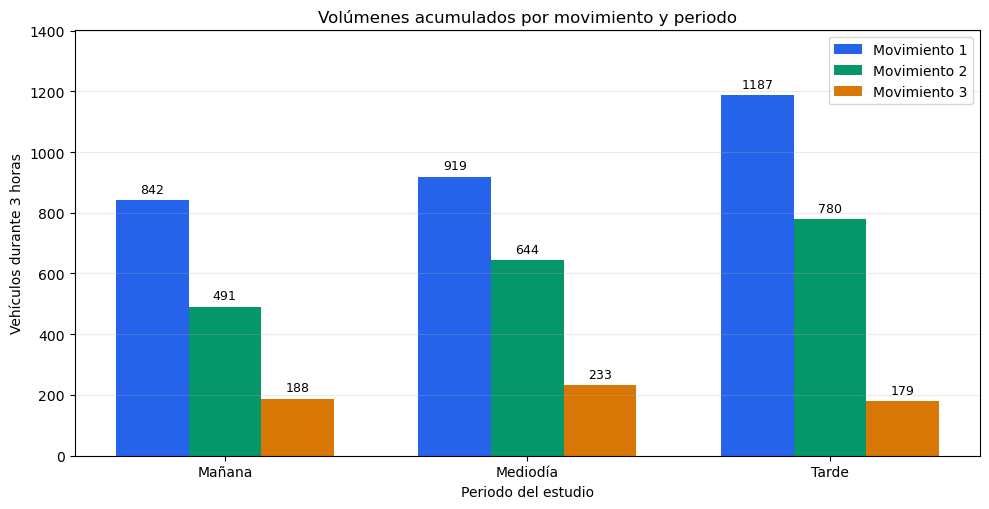

Resumen de los tres movimientos por periodo:


,Movimiento 1,Movimiento 2,Movimiento 3,Total movimientos 1–3
Periodo,,,,
Mañana,842,491,188,1521
Mediodía,919,644,233,1796
Tarde,1187,780,179,2146


Movimiento de mayor volumen en cada periodo:
- Mañana: Movimiento 1
- Mediodía: Movimiento 1
- Tarde: Movimiento 1


In [18]:
# Gráfica 2: comparación conjunta de los volúmenes registrados en tres horas
# Cada barra muestra el TOTAL de un movimiento en un periodo de 3 horas.
fig, ax = plt.subplots(figsize=(10, 5.2))
posiciones = np.arange(len(ORDEN_PERIODOS))
ancho = 0.24

for j, (movimiento, color) in enumerate(zip(movimientos, colores)):
    valores = totales_periodo.loc[ORDEN_PERIODOS, movimiento].to_numpy()
    barras = ax.bar(posiciones + (j - 1) * ancho, valores,
                    width=ancho, label=movimiento, color=color)
    ax.bar_label(barras, padding=3, fontsize=9, fmt="%.0f")

ax.set_xticks(posiciones, ORDEN_PERIODOS)
ax.set_ylim(0, totales_periodo[movimientos].to_numpy().max() * 1.18)
ax.set_title("Volúmenes acumulados por movimiento y periodo")
ax.set_ylabel("Vehículos durante 3 horas")
ax.set_xlabel("Periodo del estudio")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print("Resumen de los tres movimientos por periodo:")
display(totales_periodo.astype(int))
print("Movimiento de mayor volumen en cada periodo:")
for periodo in ORDEN_PERIODOS:
    ganador = totales_periodo.loc[periodo, movimientos].idxmax()
    print(f"- {periodo}: {ganador}")

### Interpretación 2. Comportamiento del tráfico

¿Cuál movimiento presenta mayor volumen? El Movimiento 1 es el de mayor volumen en los tres periodos: 842 vehículos en la mañana, 919 al mediodía y 1,187 por la tarde. Le sigue el Movimiento 2 con 491, 644 y 780, respectivamente. El Movimiento 3 presenta 188, 233 y 179 vehículos.

¿En qué intervalo se observa la mayor demanda? Si se suman los tres movimientos, los intervalos de 15 minutos más cargados son 09:00–09:15 en la mañana (164 vehículos), 13:00–13:15 al mediodía (183) y 17:30–17:45 por la tarde (206). Este último es el mayor de los 36 intervalos estudiados.

Es importante no confundir estos máximos de 15 minutos con las horas pico de la intersección completa: 08:00–09:00 (1,771 vehículos), 13:45–14:45 (2,287) y 17:15–18:15 (2,372). En esas mismas ventanas, los movimientos 1–3 aportan 548, 619 y 722 vehículos, respectivamente.

¿Los movimientos se comportan de manera similar? No completamente. Del periodo matutino al vespertino aumentan los acumulados de los movimientos 1 y 2, pero el Movimiento 3 alcanza su mayor acumulado al mediodía y desciende a 179 vehículos por la tarde. Tampoco todos presentan sus máximos individuales a la misma hora.

¿Qué diferencias se encuentran? La demanda del Movimiento 1 es la más alta durante todo el día; la del Movimiento 2 aumenta de manera importante hacia la tarde, mientras que el Movimiento 3 representa un volumen menor y tiene un comportamiento diferente. El volumen conjunto de los tres movimientos aumenta de 1,521 a 1,796 y luego a 2,146 vehículos entre los tres periodos.

¿Por qué importa para los tiempos de verde? La demanda es desigual entre movimientos y periodos, por lo que un control semafórico podría necesitar adaptarse. Sin embargo, no basta con asignar más segundos al movimiento de mayor volumen: también son necesarias las capacidades de carril, las colas, las fases compatibles y las restricciones de seguridad y cruces peatonales.

### Intervalos de mayor demanda entre los tres movimientos

,Mayor intervalo 15 min,Vehículos en 15 min (mov. 1–3),Movimiento mayor en 3 h
Periodo,,,
Mañana,09:00–09:15,164,Movimiento 1
Mediodía,13:00–13:15,183,Movimiento 1
Tarde,17:30–17:45,206,Movimiento 1


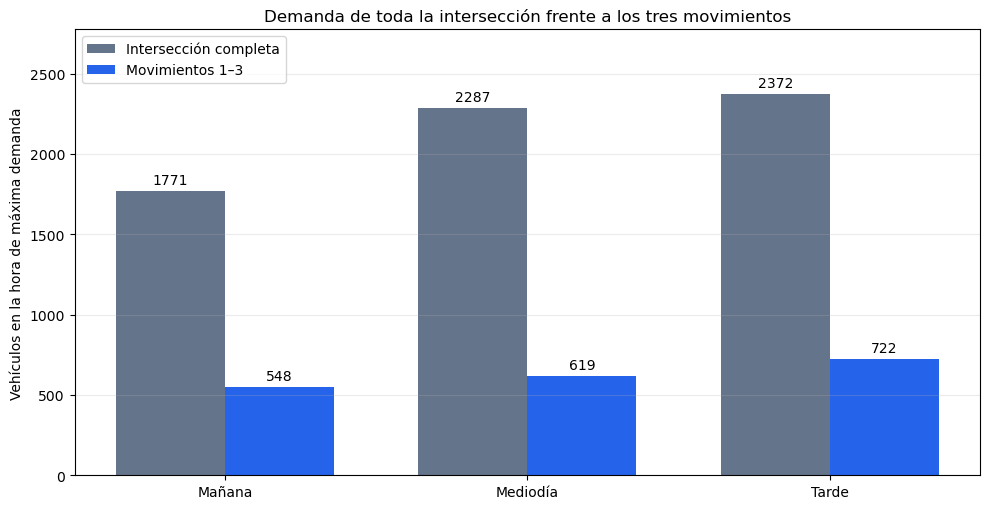

Las barras son conteos de UNA HORA, no sumas de tres horas.
Los tres totales generales corresponden a ventanas móviles de 60 min.


In [19]:
# Resúmenes complementarios para interpretar las gráficas sin confundir escalas
detalle_maximos = []
for info in PERIODOS:
    periodo = info["periodo"]
    sub = datos.loc[datos["Periodo"] == periodo].copy()
    fila = sub.loc[sub["Suma de tres movimientos"].idxmax()]
    detalle_maximos.append({
        "Periodo": periodo,
        "Mayor intervalo 15 min": f"{fila['Intervalo']}–{fila['Fin']}",
        "Vehículos en 15 min (mov. 1–3)": int(fila["Suma de tres movimientos"]),
        "Movimiento mayor en 3 h":
            totales_periodo.loc[periodo, movimientos].idxmax()
    })
display(Markdown("### Intervalos de mayor demanda entre los tres movimientos"))
display(pd.DataFrame(detalle_maximos).set_index("Periodo"))

# Gráfica 3: proporción de los tres movimientos dentro de la hora pico GENERAL
fig, ax = plt.subplots(figsize=(10, 5.2))
xp = np.arange(len(ORDEN_PERIODOS))
todo = picos.loc[ORDEN_PERIODOS, "Intersección completa"].to_numpy()
parte = picos.loc[ORDEN_PERIODOS, "Movimientos 1–3 en esa hora"].to_numpy()

barras1 = ax.bar(xp - 0.18, todo, width=0.36, label="Intersección completa",
                 color="#64748b")
barras2 = ax.bar(xp + 0.18, parte, width=0.36, label="Movimientos 1–3",
                 color="#2563eb")
ax.bar_label(barras1, padding=3, fmt="%d")
ax.bar_label(barras2, padding=3, fmt="%d")
ax.set_xticks(xp, ORDEN_PERIODOS)
ax.set_ylabel("Vehículos en la hora de máxima demanda")
ax.set_title("Demanda de toda la intersección frente a los tres movimientos")
ax.set_ylim(0, max(todo) * 1.17)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print("Las barras son conteos de UNA HORA, no sumas de tres horas.")
print("Los tres totales generales corresponden a ventanas móviles de 60 min.")

---

## Parte 3. Normalización conjunta de los datos

Para comparar los tres periodos, la función Min-Max se ajusta una sola vez para cada movimiento utilizando conjuntamente sus 36 registros, sin reiniciar el mínimo y el máximo al cambiar de periodo:

\[
x_{\text{normalizado}}=\frac{x-x_{\min}}{x_{\max}-x_{\min}}.
\]

Así se conservan las diferencias relativas de nivel entre mañana, mediodía y tarde, además de las fluctuaciones dentro de cada periodo. Si se normalizara cada periodo por separado, los tres periodos mostrarían máximos de 1 incluso cuando sus volúmenes reales fueran diferentes, dificultando una comparación entre horarios.

Cuando una serie es constante se le asigna 0 a sus valores válidos para evitar dividir entre cero, dejando constancia de ello.

Esta transformación es exclusivamente didáctica. Para una MLP real, el escalador debe ajustarse solo con datos de entrenamiento y reutilizarse para validación y prueba, sin fuga de información.

In [20]:
# Normalización global por movimiento (36 registros combinados).
# Se conservan los valores originales y el periodo de cada observación.
normalizados = pd.DataFrame(index=datos.index)
minmax = []
constantes = []

for movimiento in movimientos:
    serie = datos[movimiento].astype(float)
    minimo, maximo = serie.min(), serie.max()
    rango = maximo - minimo

    if np.isclose(rango, 0):
        normalizados[movimiento] = serie.apply(
            lambda x: np.nan if pd.isna(x) else 0.0
        )
        constantes.append(movimiento)
    else:
        normalizados[movimiento] = (serie - minimo) / rango

    minmax.append({
        "Movimiento": movimiento,
        "Mínimo conjunto": minimo,
        "Máximo conjunto": maximo
    })

display(Markdown("### Extremos de Min-Max calculados con los tres periodos"))
display(pd.DataFrame(minmax))

tabla_normalizacion = datos[["Periodo", "Intervalo"]].copy()
for movimiento in movimientos:
    tabla_normalizacion[f"{movimiento} original"] = datos[movimiento]
    tabla_normalizacion[f"{movimiento} Min-Max"] = normalizados[movimiento]

display(Markdown("### Valores originales y transformados: 36 registros"))
display(tabla_normalizacion.round(4))
print("Movimientos constantes:", constantes or "ninguno")

valores = normalizados.to_numpy(dtype=float)
finitos = valores[np.isfinite(valores)]
assert len(finitos) > 0
assert (finitos >= -1e-10).all()
assert (finitos <= 1 + 1e-10).all()

### Extremos de Min-Max calculados con los tres periodos

,Movimiento,Mínimo conjunto,Máximo conjunto
0,Movimiento 1,39.0,119.0
1,Movimiento 2,20.0,81.0
2,Movimiento 3,5.0,28.0


### Valores originales y transformados: 36 registros

,Periodo,Intervalo,Movimiento 1 original,Movimiento 1 Min-Max,Movimiento 2 original,Movimiento 2 Min-Max,Movimiento 3 original,Movimiento 3 Min-Max
0,Mañana,07:00,39.0,0.0000,20.0,0.0000,8.0,0.1304
1,Mañana,07:15,59.0,0.2500,32.0,0.1967,12.0,0.3043
2,Mañana,07:30,86.0,0.5875,38.0,0.2951,17.0,0.5217
3,Mañana,07:45,60.0,0.2625,47.0,0.4426,28.0,1.0000
4,Mañana,08:00,72.0,0.4125,60.0,0.6557,20.0,0.6522
5,Mañana,08:15,57.0,0.2250,37.0,0.2787,14.0,0.3913
6,Mañana,08:30,89.0,0.6250,39.0,0.3115,20.0,0.6522
7,Mañana,08:45,73.0,0.4250,43.0,0.3770,24.0,0.8261
8,Mañana,09:00,75.0,0.4500,72.0,0.8525,17.0,0.5217
9,Mañana,09:15,76.0,0.4625,32.0,0.1967,12.0,0.3043


Movimientos constantes: ninguno


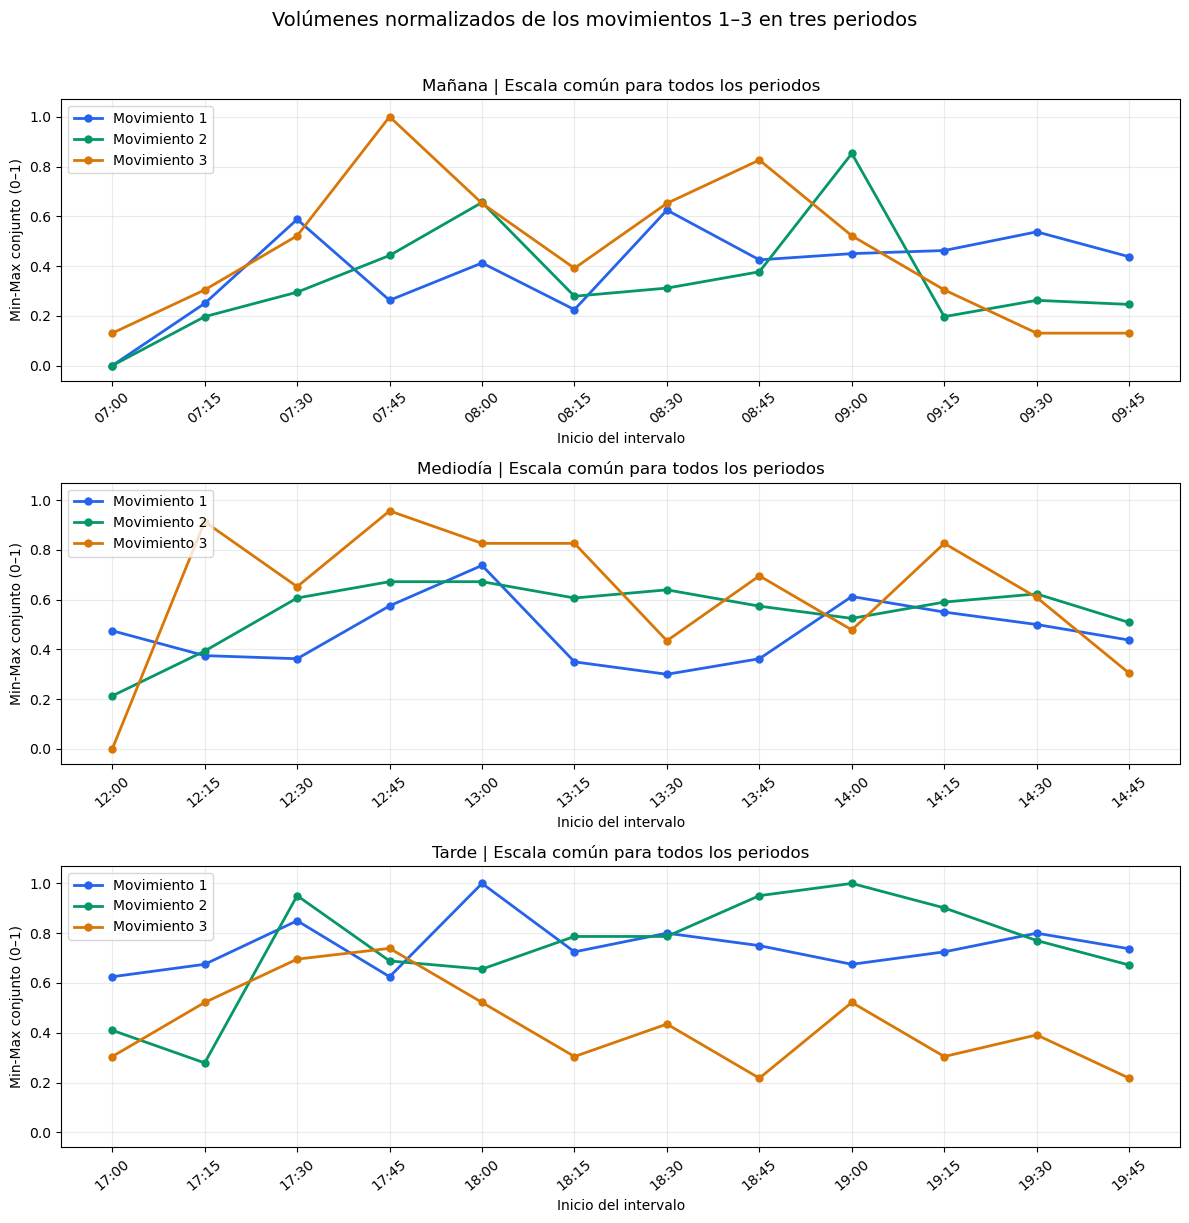

In [21]:
# Gráfica 4: comparación de Min-Max sin reajustar la escala en cada periodo
fig, ejes = plt.subplots(3, 1, figsize=(12, 12), sharey=True)

for ax, info in zip(ejes, PERIODOS):
    periodo = info["periodo"]
    mascara = datos["Periodo"] == periodo
    sub = datos.loc[mascara]
    for movimiento, color in zip(movimientos, colores):
        ax.plot(sub["Intervalo"], normalizados.loc[mascara, movimiento],
                marker="o", linewidth=2, markersize=5,
                label=movimiento, color=color)
    ax.set_title(f"{periodo} | Escala común para todos los periodos")
    ax.set_ylabel("Min-Max conjunto (0–1)")
    ax.set_ylim(-0.06, 1.07)
    ax.set_xlabel("Inicio del intervalo")
    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", labelrotation=40)
    ax.legend(loc="upper left")

fig.suptitle("Volúmenes normalizados de los movimientos 1–3 en tres periodos",
             fontsize=14, y=1.015)
plt.tight_layout()
plt.show()

### Interpretación 3. Normalización

¿Qué cambió después de normalizar? Cada movimiento pasó de expresarse en vehículos por 15 minutos a una escala de 0 a 1. Los mínimos y máximos se calcularon usando los 36 registros de los tres periodos conjuntamente, no de forma independiente para cada periodo. Los extremos fueron 39–119 vehículos para el Movimiento 1, 20–81 para el 2 y 5–28 para el 3.

¿Se conservaron los patrones? Sí. La transformación Min-Max es lineal creciente cuando el rango no es cero; por eso conserva la ubicación de las subidas, bajadas y máximos en la gráfica. Por ejemplo, el Movimiento 1 alcanza su valor normalizado 1 a las 18:00 (119 vehículos), el Movimiento 2 a las 19:00 (81) y el Movimiento 3 a las 07:45 (28).

¿Por qué es útil para una MLP? Tener variables en rangos comparables puede mejorar la estabilidad del entrenamiento y evitar que alguna entrada domine solo por la magnitud de su escala numérica. No sustituye una buena selección de variables ni datos suficientes.

¿Significa que todos los movimientos tienen el mismo volumen? No. Dos movimientos con valor normalizado 1 pueden representar conteos diferentes. Igualmente, el valor 0 representa el mínimo observado, no necesariamente ausencia de vehículos: para el Movimiento 3, cero corresponde a 5 vehículos en el intervalo de las 12:00.

¿Y si un movimiento tuviera volumen constante? Se asignaría 0 a sus observaciones válidas para evitar la división entre cero y se dejaría constancia de que no presentó variación.

En este ejercicio se normalizó para explorar el conjunto completo. Si posteriormente se entrena una MLP, los mínimos y máximos deben ajustarse solo con los datos de entrenamiento y reutilizarse sin reajuste en validación y prueba.

---

## Parte 4. Identificación de patrones para una futura MLP

### Variables candidatas y su aportación

| Variable | Información que aportaría |
|---|---|
| Volumen del Movimiento 1 por intervalo | Demanda de la corriente con mayor volumen acumulado en los tres periodos. |
| Volumen del Movimiento 2 por intervalo | Variaciones de una segunda corriente cuya demanda aumenta hacia la tarde. |
| Volumen del Movimiento 3 por intervalo | Demanda de una tercera corriente, que presenta su mayor acumulado al mediodía. |
| Hora y periodo del día | Patrones temporales y diferencias de demanda entre mañana, mediodía y tarde. |
| Ocupación, longitud de cola y demanda peatonal | Información adicional sobre congestión y necesidades de servicio que no aparece en los conteos utilizados. |

La red podría intentar aprender relaciones entre el momento del día, la demanda por movimiento y los tiempos de verde adecuados. Por ejemplo, los registros muestran que la suma de los movimientos 1–3 es mayor durante la tarde, pero la tercera corriente no sigue ese aumento. Estas diferencias podrían ser importantes para elegir una distribución de servicio.

### Entradas, objetivos y restricciones

Los volúmenes y las variables de estado del tráfico serían entradas del modelo. Las etiquetas objetivo serían tiempos de verde o splits por fase, obtenidos de decisiones operativas válidas, registros de control o un procedimiento de optimización debidamente validado.

Los tres archivos Excel muestran aforos, no tiempos de verde recomendados. No es correcto inventar etiquetas solo a partir de los volúmenes. También se necesitan límites mínimos y máximos de verde, fases compatibles, intervalos de amarillo y todo-rojo, tiempos peatonales y reglas del controlador.

### Interpretación 4. Conexión con las redes neuronales

¿Qué datos usaría como entradas de una MLP? Los tres volúmenes por intervalo y el momento del día. Para una solución más completa incorporaría los demás movimientos de la intersección, ocupación, longitudes de cola, velocidades, demanda peatonal y la fase semafórica actual.

¿Qué me gustaría que aprendiera a predecir? Segundos de verde por fase o splits recomendados que respondan a los cambios de demanda y respeten las reglas operativas.

¿Contamos con las etiquetas necesarias? No. Los libros proporcionan mediciones de vehículos, pero no etiquetas verificadas de tiempos de verde recomendados para esos mismos intervalos. Por lo tanto, los aforos no son suficientes para entrenar una MLP supervisada que prediga splits.

¿Qué diferencia hay entre observar un patrón y demostrar que la red lo aprendió? Las gráficas muestran que los movimientos tienen volúmenes y picos distintos en estas observaciones. Que una red aprenda requeriría ajustar sus parámetros y demostrar que realiza predicciones útiles sobre otros días o escenarios no utilizados en el entrenamiento.

¿Cómo comprobaría que generaliza? Reuniría más días y condiciones de demanda; separaría entrenamiento, validación y prueba de manera temporal; ajustaría la normalización solo con entrenamiento y evaluaría errores de predicción de tiempos de verde mediante MAE o RMSE. Posteriormente compararía la política propuesta con alternativas en una simulación calibrada, evaluando demora, longitud de colas, detenciones y seguridad.

### Verificación final del análisis conjunto

Las verificaciones comprueban que se cargaron los tres Excel y que se obtuvieron 36 intervalos válidos (12 por periodo) para los movimientos 1, 2 y 3. Asimismo, confirman las horas pico de la intersección completa frente al croquis.

Las cuatro interpretaciones y la conclusión de este notebook se actualizaron utilizando los resultados de las tres corridas. Las gráficas y las tablas de las celdas anteriores conservan los resultados ejecutados y publicados en GitHub.

In [ ]:
# Validación final reproducible para los tres periodos combinados
hojas_esperadas = ["Hora Máx.", *[str(i) for i in range(1, 15)], "Vol. Dir."]
for periodo, libro in libros.items():
    assert libro.sheet_names == hojas_esperadas, f"Hojas inesperadas en {periodo}"

assert len(datos) == 36
assert (datos.groupby("Periodo", observed=True).size() == 12).all()
assert not datos[movimientos].isna().any().any()
assert len(registro_reconstrucciones) == 9  # 3 movimientos x 3 periodos
assert normalizados.shape == (36, 3)

assert picos.loc[ORDEN_PERIODOS, "Intersección completa"].astype(int).tolist() == [
    1771, 2287, 2372
]
assert picos.loc[ORDEN_PERIODOS, "Hora pico inicio"].tolist() == [
    "08:00", "13:45", "17:15"
]

print("Validación satisfactoria de tres Excel y tres periodos.")
print("Total:", len(datos), "intervalos con tres movimientos por intervalo.")
print("Se generaron tablas comparativas y gráficas de volúmenes originales y normalizados.")
print("Los tres máximos horarios coinciden con el croquis.")
print("Todavía no se entrenó una red neuronal.")
print("Interpretaciones y conclusión revisadas a partir de los tres periodos.")

---

## Conclusión: ¿qué aprendí sobre los datos de tráfico?

Esta actividad me permitió comprender mejor cómo cambia el tránsito durante el día y por qué es importante estudiar los datos antes de construir una red neuronal. Al integrar los tres archivos de la intersección 01, pude comparar 36 intervalos de 15 minutos correspondientes a la mañana, el mediodía y la tarde.

Observé que los movimientos no tienen el mismo comportamiento. El Movimiento 1 fue el de mayor volumen en los tres periodos y alcanzó 1,187 vehículos por la tarde. El Movimiento 2 también aumentó, de 491 vehículos por la mañana a 780 por la tarde. En cambio, el Movimiento 3 registró su mayor acumulado al mediodía, con 233 vehículos. Además, el intervalo con mayor demanda conjunta de estos tres movimientos fue de 17:30 a 17:45, con 206 vehículos.

La normalización Min-Max me permitió comparar las fluctuaciones en una escala común sin perder de vista que valores normalizados iguales pueden representar cantidades de vehículos distintas.

Para el reto de SEMEX, entendí que estos patrones pueden ser útiles como entradas de una MLP, pero todavía necesitamos datos de colas y ocupación, etiquetas de tiempos de verde y restricciones de seguridad. Predecir un tiempo de verde no demuestra por sí solo que se reduzcan las demoras: esa utilidad tendría que validarse con datos nuevos y simulaciones.